In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from adjustText import adjust_text

In [2]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'development', 'modeling')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'mesencoder', 'bifurcation')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'mesencoder.h5ad'))
adata

AnnData object with n_obs × n_vars = 6405 × 510
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 't_orig', 'early', 'late', 'spectrum', 't', 'seg', 'edge', 'milestones'
    uns: 'celltype_colors', 'graph', 'milestones_colors', 'pseudotime_list', 'seg_colors'
    obsm: 'X_R', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_spectrum', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

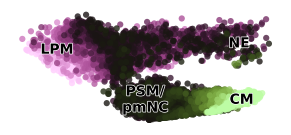

In [4]:
# plot spectrum
fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = .8, color = 't',
                cmap = 'vanimo', colorbar_loc = None,
                frameon = False, show = False, ax = ax)
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = 0, color = 'celltype',
                legend_loc = 'on data', legend_fontoutline = 1,
                frameon = False, show = False, ax = ax)
ax.set_title(''); ax.invert_yaxis()

label_dict = {
    'Cranial Mesenchyme'         : 'CM',
    'Lateral Plate Mesoderm'     : 'LPM',
    'Migratory Neural Crest'     : '',
    'nan'                        : '',
    'Nascent Endothelium'        : 'NE',
    'Neuroglial Progenitors'     : '',
    'Neuromesodermal Progenitor' : '',
    'Premigratory Neural Crest'  : '',
    'Presomitic Mesoderm'        : 'PSM/\npmNC',
    'Somite'                     : ''}

pos_dict = {
    'Cranial Mesenchyme'     : (.1, 0),
    'Lateral Plate Mesoderm' : (-.925, .05),
    'Nascent Endothelium'    : (.75, .05),
    'Presomitic Mesoderm'    : (-.125, 0)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_out, 'spectrum.pdf')
plt.savefig(fn, bbox_inches = 'tight')

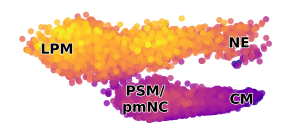

In [5]:
# plot Mes1 signature
fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = .8, color = 'GSE162534',
                cmap = 'plasma', colorbar_loc = None,
                frameon = False, show = False, ax = ax)
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = 0, color = 'celltype',
                legend_loc = 'on data', legend_fontoutline = 1,
                frameon = False, show = False, ax = ax)
ax.set_title(''); ax.invert_yaxis()

label_dict = {
    'Cranial Mesenchyme'         : 'CM',
    'Lateral Plate Mesoderm'     : 'LPM',
    'Migratory Neural Crest'     : '',
    'nan'                        : '',
    'Nascent Endothelium'        : 'NE',
    'Neuroglial Progenitors'     : '',
    'Neuromesodermal Progenitor' : '',
    'Premigratory Neural Crest'  : '',
    'Presomitic Mesoderm'        : 'PSM/\npmNC',
    'Somite'                     : ''}

pos_dict = {
    'Cranial Mesenchyme'     : (.1, 0),
    'Lateral Plate Mesoderm' : (-.925, .05),
    'Nascent Endothelium'    : (.75, .05),
    'Presomitic Mesoderm'    : (-.125, 0)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_out, 'Mes1.pdf')
plt.savefig(fn, bbox_inches = 'tight')

/tmp/ipykernel_677156/2926858493.py:3: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax = cax)


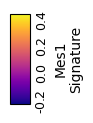

In [6]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax)
cb.ax.tick_params(which = 'both', size = 0, rotation = 90, labelsize = 9)
cb.set_label('Mes1\nSignature')
cb.set_ticks([-.2, 0, .2, .4], labels = [r'$\text{-}$0.2', '0.0', .2, .4])
cb.solids.set_alpha(1)
fn = os.path.join(pth_out, 'colorbars', 'Mes1.pdf')
plt.savefig(fn, bbox_inches = 'tight')

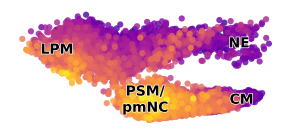

In [7]:
# plot Mes2 signature
fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = .8, color = 'GSE229103',
                cmap = 'plasma', colorbar_loc = None,
                frameon = False, show = False, ax = ax)
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = 0, color = 'celltype',
                legend_loc = 'on data', legend_fontoutline = 1,
                frameon = False, show = False, ax = ax)
ax.set_title(''); ax.invert_yaxis()

label_dict = {
    'Cranial Mesenchyme'         : 'CM',
    'Lateral Plate Mesoderm'     : 'LPM',
    'Migratory Neural Crest'     : '',
    'nan'                        : '',
    'Nascent Endothelium'        : 'NE',
    'Neuroglial Progenitors'     : '',
    'Neuromesodermal Progenitor' : '',
    'Premigratory Neural Crest'  : '',
    'Presomitic Mesoderm'        : 'PSM/\npmNC',
    'Somite'                     : ''}

pos_dict = {
    'Cranial Mesenchyme'     : (.1, 0),
    'Lateral Plate Mesoderm' : (-.925, .05),
    'Nascent Endothelium'    : (.75, .05),
    'Presomitic Mesoderm'    : (-.125, 0)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_out, 'Mes2.pdf')
plt.savefig(fn, bbox_inches = 'tight')

/tmp/ipykernel_677156/1607085871.py:3: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax = cax)


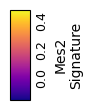

In [8]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax)
cb.ax.tick_params(which = 'both', size = 0, rotation = 90, labelsize = 9)
cb.set_label('Mes2\nSignature')
cb.set_ticks([0, .2, .4])
cb.solids.set_alpha(1)
fn = os.path.join(pth_out, 'colorbars', 'Mes2.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [9]:
# select: LPM/NE (branch), Mes1+2 (genes)
mod_early = ('GSE162534', 'GSE229103')
get_pth = lambda src: os.path.join(pth_feat, f'{src}.csv')
get_feat = lambda pth: pd.read_csv(pth).mmusculus.values
feat_dict = {src : get_feat(get_pth(src)) for src in mod_early}
g = np.union1d(feat_dict[mod_early[0]], feat_dict[mod_early[1]])
adata1 = adata[(adata.obs.source == 'GSE162534'), g].copy()
adata1

AnnData object with n_obs × n_vars = 2811 × 338
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 't_orig', 'early', 'late', 'spectrum', 't', 'seg', 'edge', 'milestones'
    uns: 'celltype_colors', 'graph', 'milestones_colors', 'pseudotime_list', 'seg_colors'
    obsm: 'X_R', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_spectrum', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

In [10]:
# compute neighbors & pseudotime windows
sc.pp.neighbors(adata1, 200, use_rep = 'X_mesencoder')
adata1.obs['t_bin'] = pd.cut(adata1.obs.t_orig,
                             bins = 7,
                             labels = False)
adata1.obs['t_bin'] = adata1.obs.t_bin.astype(str)

# mutual negative correlation (windowed)
r_dict = dict()
for bin, sdf in adata1.obs.groupby('t_bin', observed = True):
    adata_bin = adata1[sdf.index].copy()
    X = pd.DataFrame(adata_bin.X.toarray(),
                     index = sdf.index,
                     columns = adata1.var_names)
    X = X.loc[:, (X.nunique(axis = 0) > 1)].copy()
    mod1 = sdf[mod_early[0]].values[:, None]
    mod2 = sdf[mod_early[1]].values[:, None]
    a = pearsonr(X, mod1, axis = 0).statistic
    b = pearsonr(X, mod2, axis = 0).statistic
    r_dict[bin] = -np.corrcoef(a, b)[0, 1]

# smoothing (neighbors)
A = adata1.obsp['connectivities']
R = adata1.obs.t_bin.map(r_dict)
R_sm = (A @ R) / A.sum(axis = 1).A1
adata1.obs['correlation'] = R_sm

In [11]:
adata1.write(os.path.join(pth_in, 'bifurcation.h5ad'))

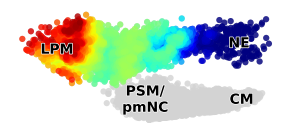

In [12]:
# plot negative correlation
fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = .8, frameon = False,
                show = False, ax = ax)
sc.pl.embedding(adata1, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = .8, color = 'correlation',
                cmap = 'jet', colorbar_loc = None,
                frameon = False, show = False, ax = ax)
sc.pl.embedding(adata, 'X_mesencoder', dimensions = [1, 0],
                size = 80, alpha = 0, color = 'celltype',
                legend_loc = 'on data', legend_fontoutline = 1,
                frameon = False, show = False, ax = ax)
ax.set_title(''); ax.invert_yaxis()

label_dict = {
    'Cranial Mesenchyme'         : 'CM',
    'Lateral Plate Mesoderm'     : 'LPM',
    'Migratory Neural Crest'     : '',
    'nan'                        : '',
    'Nascent Endothelium'        : 'NE',
    'Neuroglial Progenitors'     : '',
    'Neuromesodermal Progenitor' : '',
    'Premigratory Neural Crest'  : '',
    'Presomitic Mesoderm'        : 'PSM/\npmNC',
    'Somite'                     : ''}

pos_dict = {
    'Cranial Mesenchyme'     : (.1, 0),
    'Lateral Plate Mesoderm' : (-.925, .05),
    'Nascent Endothelium'    : (.75, .05),
    'Presomitic Mesoderm'    : (-.125, 0)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_out, 'correlation.pdf')
plt.savefig(fn, bbox_inches = 'tight')

/tmp/ipykernel_677156/105793457.py:3: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[1], cax = cax)


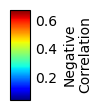

In [13]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[1], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Negative\nCorrelation')
cb.set_ticks([.2, .4, .6])
cb.solids.set_alpha(1)
fn = os.path.join(pth_out, 'colorbars', 'correlation.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [14]:
# select: early cells (only)
adata1_early = adata1[adata1.obs.t_bin.isin(['0', '1'])].copy()
adata1_early

AnnData object with n_obs × n_vars = 792 × 338
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 't_orig', 'early', 'late', 'spectrum', 't', 'seg', 'edge', 'milestones', 't_bin', 'correlation'
    uns: 'celltype_colors', 'graph', 'milestones_colors', 'pseudotime_list', 'seg_colors', 'neighbors'
    obsm: 'X_R', 'X_mesencoder', 'X_pca', 'X_pca_harmony', 'X_spectrum', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'
    obsp: 'distances', 'connectivities'

In [15]:
# compute module correlations
X = pd.DataFrame(adata1_early.X.toarray(),
                 index = adata1_early.obs_names,
                 columns = adata1.var_names)
X = X.loc[:, (X.nunique(axis = 0) > 1)].copy()
R = pd.DataFrame(index = X.columns)
mod1 = adata1_early.obs[mod_early[0]].values[:, None]
mod2 = adata1_early.obs[mod_early[1]].values[:, None]
R['Mes1'] = pearsonr(X, mod1, axis = 0).statistic
R['Mes2'] = pearsonr(X, mod2, axis = 0).statistic
rank = (R.Mes2 - R.Mes1).rank().astype(int)
R = R.loc[rank.sort_values().index].copy()

# module labels
msk1 = R.index.isin(feat_dict[mod_early[0]])
msk2 = R.index.isin(feat_dict[mod_early[1]])
msk_dict = {'Mes1' : msk1 & ~msk2,
            'Mes2' : ~msk1 & msk2,
            'Both' : msk1 & msk2}
for mod, msk in msk_dict.items():
    R.loc[msk, 'Module'] = mod
    print(mod, msk.sum())
R['Module'] = pd.Categorical(R.Module,
                             reversed(msk_dict.keys()),
                             ordered = True)

Mes1 139
Mes2 134
Both 59


In [16]:
c_dict = {'Mes1' : 'magenta',
          'Mes2' : 'lime',
          'Both' : 'darkgrey'}

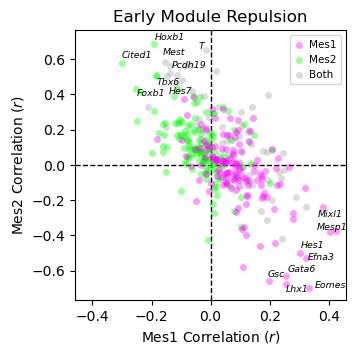

In [17]:
# plot early module repulsion
fig, ax = plt.subplots(1, 1, figsize = (3.5, 3.5))
for mod, sdf in R.groupby('Module', observed = True):
    sdf.plot(kind = 'scatter', x = 'Mes1', y = 'Mes2',
             color = c_dict[mod], label = mod, s = 25,
             alpha = .4, linewidth = 0, ax = ax)
ax.axvline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
ax.axhline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
xlim = abs(np.asarray(ax.get_xlim())).max()
ylim = abs(np.asarray(ax.get_ylim())).max()
ax.set_xlim(-xlim, xlim); ax.set_ylim(-ylim, ylim)

# label top genes
n, fs, texts = 8, 6.75, list()
for ix in R.head(n).index:
    texts.append(ax.text(
        R.loc[ix].Mes1,
        R.loc[ix].Mes2,
        ix, fontsize = fs,
        fontstyle = 'italic'))
for ix in R.tail(n).index:
    texts.append(ax.text(
        R.loc[ix].Mes1,
        R.loc[ix].Mes2,
        ix, fontsize = fs,
        fontstyle = 'italic'))
adjust_text(texts = texts)

for label in texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in ('T', 'Pcdh19'):
        label.set_position([x -.025, y])

ax.legend(handlelength = 1,
          handletextpad = .5,
          fontsize = 7.5,
          reverse = True)

ax.set_title('Early Module Repulsion')
ax.set_xlabel(r'Mes1 Correlation ($r$)')
ax.set_ylabel(r'Mes2 Correlation ($r$)')
fn = os.path.join(pth_out, 'repulsion.pdf')
plt.savefig(fn, bbox_inches = 'tight')